# Science case: TDAMM follow-up (transient classification)

Time-domain and multi-messenger (TDAMM) follow-up with a spectrograph is mostly about
**classification**: a low-SNR spectrum, rebinned to R ~ 100-300, that distinguishes a SN Ia from a
SN II, a kilonova from an afterglow, or a TDE from an AGN flare. The relevant question for LFAST
is: *how faint a transient can we classify in a given exposure, and how quickly?*

**Assumptions used here** (knobs):

* Classification needs SNR ~ 5 per **rebinned** element at R_bin = 300 across 450-650 nm, the
  regime low-resolution classifiers are designed for (SEDM: Blagorodnova et al. 2018; 4MOST/TiDES:
  Swann et al. 2019). Co-adding $k = R/R_{bin}$ adjacent resels of equal SNR raises the SNR by
  exactly $\sqrt{k}$ in this noise model (every variance term scales with the number of pixels).
* Transient SEDs: a hot blue blackbody (12,000 K, young SN / shock cooling), a 6000 K blackbody
  (SN Ia near peak) and a cool red 3500 K blackbody (late kilonova / SN II late). A power-law
  $F_\nu \propto \nu^{-0.7}$ represents a GRB afterglow. Magnitudes are **R** (Cousins; within
  ~0.1-0.2 mag of SDSS r for these colours), so the SED colour matters in the 450-650 nm window.
* Kilonova: AT2017gfo-like: r ~ 17.3 at ~1 d at 40 Mpc ($M_r$ ~ -15.8 to -16), fading ~0.6 mag/day
  in r over days 1-7 (Drout et al. 2017; Villar et al. 2017), cooling from ~10,000 K at 0.5 d to
  ~5000 K at 1.5 d and ~3000 K by 3.5 d (Drout et al. 2017; Shappee et al. 2017).
* The bundled sky table is grey time (moon up); dark-time depths are ~0.3-0.5 mag deeper at the
  faint end (see the sensitivity-map notebook).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
# ---- knobs ----
N_TEL = 20
WINDOW = (450, 650)          # nm, classification window
R_BIN = 300                  # rebinned resolution for classification
SNR_CLASS = 5                # SNR per R_BIN element needed to classify
BAND = "R"                   # magnitudes are quoted in Cousins R (~ SDSS r)

bench = LFASTETC("bench_r1800", n_telescopes=N_TEL, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
k = bench.instrument.resolving_power / R_BIN   # resels per rebinned element
snr_resel_needed = SNR_CLASS / np.sqrt(k)      # SNR per native resel that gives SNR_CLASS at R_BIN
print(f"{k:.1f} resels per R={R_BIN} bin -> need SNR {snr_resel_needed:.2f} per resel")

seds = {"blue 12,000 K": Source.blackbody(12000, 0, BAND),
        "SN Ia-like 6000 K": Source.blackbody(6000, 0, BAND),
        "red 3500 K": Source.blackbody(3500, 0, BAND),
        "afterglow Fnu~nu^-0.7": Source.powerlaw(-0.7, 0, BAND, system="AB")}

6.0 resels per R=300 bin -> need SNR 2.04 per resel


## Exposure time to classify versus magnitude

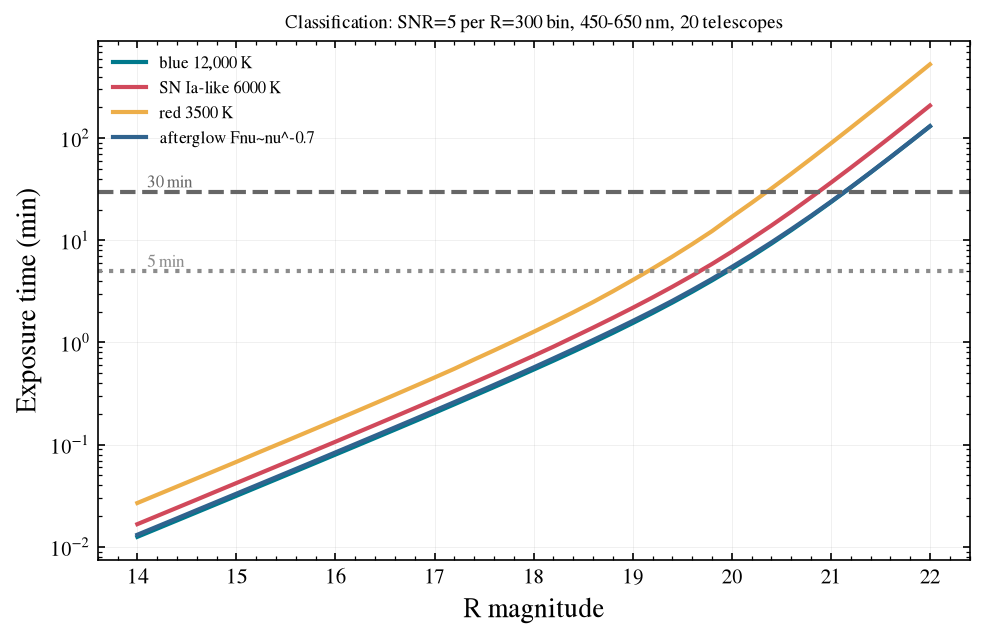

In [3]:
mags = np.linspace(14, 22, 41)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, src in seds.items():
    t = bench.exptime_vs_mag(src, mags, snr=snr_resel_needed, wavelength=WINDOW)
    ax.plot(mags, t/60, label=label)
ax.set_yscale('log'); ax.set_xlabel(f"{BAND} magnitude"); ax.set_ylabel("Exposure time (min)")
ax.axhline(30, color='0.4', ls='--'); ax.text(14.1, 33, "30 min", fontsize=8, color='0.4')
ax.axhline(5, color='0.55', ls=':'); ax.text(14.1, 5.5, "5 min", fontsize=8, color='0.55')
ax.legend(fontsize=8); ax.set_title(f"Classification: SNR={SNR_CLASS} per R={R_BIN} bin, {WINDOW[0]}-{WINDOW[1]} nm, {N_TEL} telescopes", fontsize=9);

## Classification depth versus exposure time

In [4]:
for exp in (300, 900, 1800, 3600):
    lims = [f"{label}: {BAND}<{bench.limiting_magnitude(src, exp, snr_resel_needed, wavelength=WINDOW):.1f}"
            for label, src in seds.items()]
    print(f"{exp:5d} s   " + " | ".join(lims))

  300 s   blue 12,000 K: R<20.0 | SN Ia-like 6000 K: R<19.7 | red 3500 K: R<19.2 | afterglow Fnu~nu^-0.7: R<19.9
  900 s   blue 12,000 K: R<20.7 | SN Ia-like 6000 K: R<20.4 | red 3500 K: R<19.9 | afterglow Fnu~nu^-0.7: R<20.7
 1800 s   blue 12,000 K: R<21.1 | SN Ia-like 6000 K: R<20.9 | red 3500 K: R<20.4 | afterglow Fnu~nu^-0.7: R<21.1
 3600 s   blue 12,000 K: R<21.6 | SN Ia-like 6000 K: R<21.3 | red 3500 K: R<20.8 | afterglow Fnu~nu^-0.7: R<21.6


## Kilonova: how many days after merger can we still classify?

AT2017gfo at 40 Mpc: r ~ 17.3 at 1 d, fading ~0.6 mag/day in r, cooling 10,000 K -> 5000 K ->
3000 K at 0.5, 1.5 and 3.5 d (linear ramps). We scale to other distances with the distance modulus
and ask for a classification spectrum (SNR=5 at R=300) in a 30-minute exposure. The blackbody is
normalised in R (Cousins ~ SDSS r).

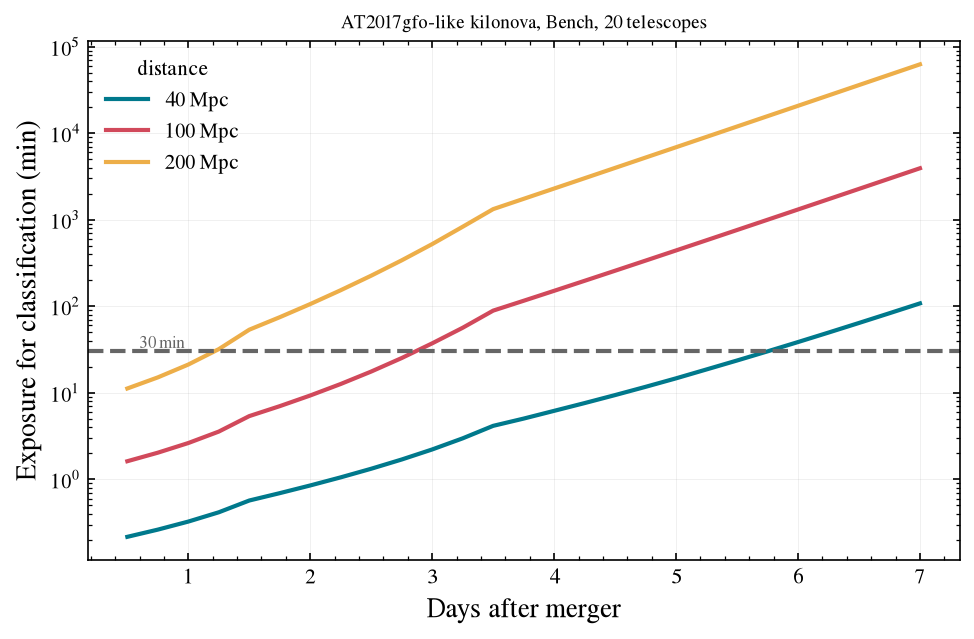

In [5]:
days = np.linspace(0.5, 7, 27)
def kn_mag(d, D_Mpc):
    return 17.3 + 0.6*(d-1.0) + 5*np.log10(D_Mpc/40)
def kn_teff(d):
    return np.interp(d, [0.5, 1.5, 3.5], [10000, 5000, 3000])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for D in (40, 100, 200):
    t_needed = np.array([bench.exptime_vs_mag(Source.blackbody(kn_teff(d), 0, BAND), [kn_mag(d, D)],
                                              snr=snr_resel_needed, wavelength=WINDOW)[0] for d in days])
    ax.plot(days, t_needed/60, label=f"{D} Mpc")
ax.axhline(30, color='0.4', ls='--'); ax.text(0.6, 33, "30 min", fontsize=8, color='0.4')
ax.set_yscale('log'); ax.set_xlabel("Days after merger"); ax.set_ylabel("Exposure for classification (min)")
ax.legend(title="distance"); ax.set_title("AT2017gfo-like kilonova, Bench, 20 telescopes", fontsize=9);

## Rapid response: a fading afterglow

GRB afterglows fade as $F \propto t^{-\alpha}$ with $\alpha \sim 1$. For an afterglow at
R = 17 (AB) one hour after the burst, how does the time-to-classify grow with the delay before LFAST
is on target?

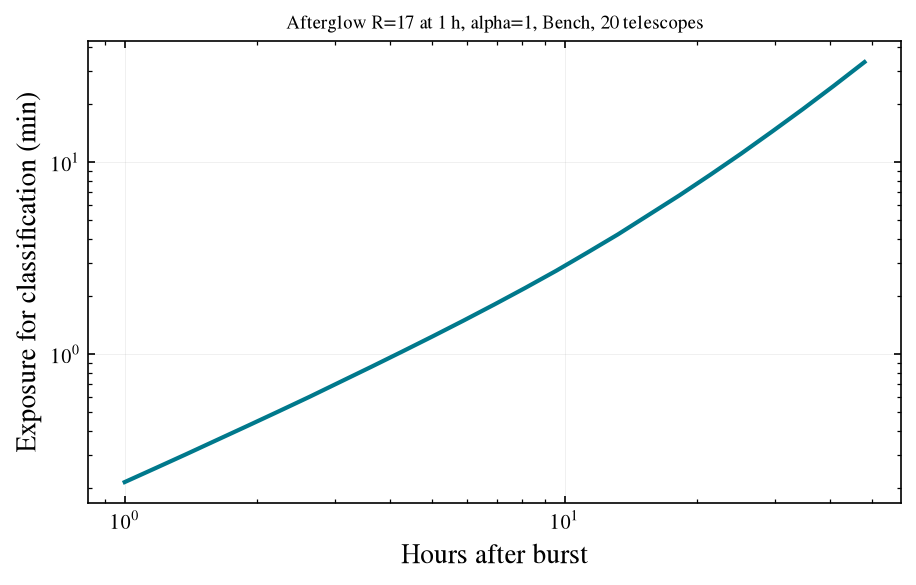

In [6]:
delay_h = np.logspace(0, np.log10(48), 25)
mag_t = 17 + 2.5*1.0*np.log10(delay_h/1.0)
t_cls = bench.exptime_vs_mag(seds["afterglow Fnu~nu^-0.7"], mag_t, snr=snr_resel_needed, wavelength=WINDOW)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(delay_h, t_cls/60)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel("Hours after burst"); ax.set_ylabel("Exposure for classification (min)")
ax.set_title("Afterglow R=17 at 1 h, alpha=1, Bench, 20 telescopes", fontsize=9);

## Array size trade for TDAMM depth (30 min, classification SNR)

In [7]:
for n in (5, 10, 20, 40, 80):
    e = LFASTETC("bench_r1800", n_telescopes=n, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
    print(f"N={n:3d}: classification depth in 30 min, 6000 K: {BAND}<{e.limiting_magnitude(seds['SN Ia-like 6000 K'], 1800, snr_resel_needed, wavelength=WINDOW):.2f}")

N=  5: classification depth in 30 min, 6000 K: R<19.97
N= 10: classification depth in 30 min, 6000 K: R<20.45
N= 20: classification depth in 30 min, 6000 K: R<20.88
N= 40: classification depth in 30 min, 6000 K: R<21.29
N= 80: classification depth in 30 min, 6000 K: R<21.69
